# Étape 1 — Chargement et Analyse exploratoire des données

Projet : **Prédiction du risque de santé mentale chez les étudiants**

## 1. Import Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Chargement du dataset

In [5]:
df = pd.read_csv("../data/student_mental_health.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 3. Comprendre la structure générale du dataset

In [6]:
print("Dimensions du dataset :", df.shape)

print("\nNoms des colonnes :")
print(df.columns.tolist())

print("\nTypes de données :")
print(df.dtypes)

df.info()

Dimensions du dataset : (2000, 17)

Noms des colonnes :
['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']

Types de données :
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                   

## 4. Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes

### 4.1 Valeurs manquantes

In [7]:
missing_values = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print(missing_values)

Valeurs manquantes par colonne :
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


### 4.2 Doublons

In [8]:
# Verifier les lignes dupliquees
print("Nombre de lignes dupliquées :", df.duplicated().sum())

# Verifier les IDs dupliquees si la colonne existe
if "Student_ID" in df.columns:
    print("Nombre d'IDs dupliquées :", df["Student_ID"].duplicated().sum())

Nombre de lignes dupliquées : 0
Nombre d'IDs dupliquées : 0


### 4.3 Incohérences dans les variables catégorielles

In [9]:
# Afficher les valeurs présentes dans chaque variable catégorielle
categorical_columns = df.select_dtypes(include=["object"]).columns
print(len(categorical_columns))
for col in categorical_columns:
    if col != "Student_ID":
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))

7

Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


C:\Users\Youcode\AppData\Local\Temp\ipykernel_34492\2344105147.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns


### 4.4 Incohérences dans les variables numériques

In [10]:
# Statistiques descriptives pour examiner les valeurs numériques
numerical_columns = df.select_dtypes(include=np.number).columns
numerical_features = [
    col for col in numerical_columns
    if col != "Student_ID"
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [11]:
# Vérifier la présence de valeurs négatives
for col in numerical_features:
    print(f"{col} :", (df[col] < 0).sum(), "valeur(s) négative(s)")

Age : 0 valeur(s) négative(s)
Year_of_Study : 0 valeur(s) négative(s)
Sleep_Hours : 0 valeur(s) négative(s)
Study_Hours_Per_Week : 0 valeur(s) négative(s)
GPA : 0 valeur(s) négative(s)
Social_Media_Hours : 0 valeur(s) négative(s)
Screen_Time_Hours : 0 valeur(s) négative(s)
Financial_Stress : 0 valeur(s) négative(s)
Family_Support : 0 valeur(s) négative(s)
Attendance_Rate : 0 valeur(s) négative(s)


### 4.5 Valeurs aberrantes (Outliers) — Boxplots

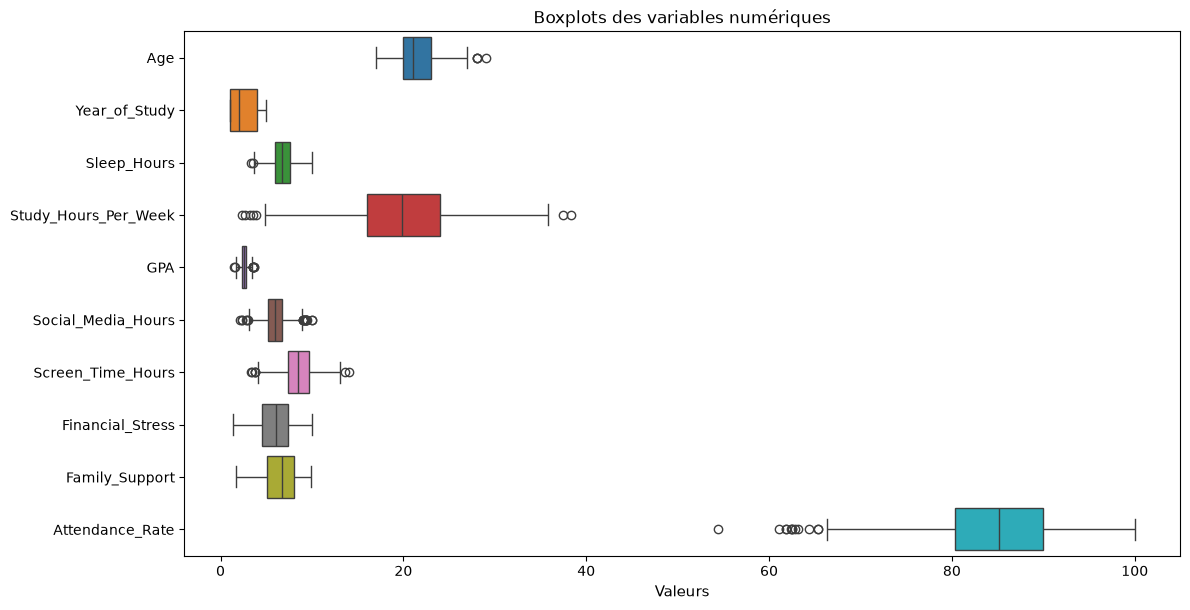

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_features], orient="h")

plt.title("Boxplots des variables numériques")
plt.tight_layout()
plt.xlabel("Valeurs", fontsize=11)
plt.show()

### 4.6 Détection des valeurs aberrantes avec la méthode IQR

In [13]:
outlier_results = []

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Number_of_Outliers": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Number_of_Outliers
0,Age,20.00,23.00,3.00,15.50,27.50,4
1,Year_of_Study,1.00,4.00,3.00,-3.50,8.50,0
2,Sleep_Hours,6.00,7.60,1.60,3.60,10.00,2
3,Study_Hours_Per_Week,16.00,24.00,8.00,4.00,36.00,7
4,GPA,2.32,2.79,0.47,1.61,3.50,9
5,Social_Media_Hours,5.22,6.70,1.48,3.01,8.91,20
6,Screen_Time_Hours,7.40,9.70,2.30,3.95,13.15,7
7,Financial_Stress,4.50,7.40,2.90,0.15,11.75,0
8,Family_Support,5.10,8.00,2.90,0.75,12.35,0
9,Attendance_Rate,80.30,90.00,9.70,65.75,104.55,12


## 5. Statistiques descriptives

In [14]:
# Statistiques descriptives des variables numériques
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [15]:
# Statistiques descriptives des variables catégorielles
categorical_features = df.select_dtypes(
    include=["str"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in ["Student_ID", "Mental_Health_Risk"]
]

df[categorical_features].describe().T

,count,unique,top,freq
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408


## 6. Étudier la distribution de la variable cible

In [16]:
target = "Mental_Health_Risk"

# Nombre d'observations dans chaque classe
print(df[target].value_counts())

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


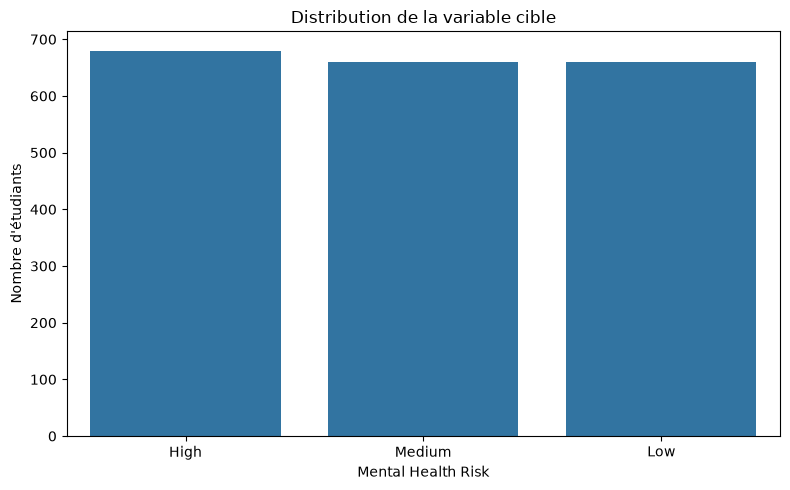

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target,
    order=df[target].value_counts().index
)

plt.title("Distribution de la variable cible")
plt.xlabel("Mental Health Risk")
plt.ylabel("Nombre d'étudiants")
plt.tight_layout()
plt.show()

## 7. Analyser les relations entre les variables explicatives et la cible

In [18]:
# Identifier les variables catégorielles et numériques
categorical_features = df.select_dtypes(
    include=["str"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in [target, "Student_ID"]
]

numerical_features = df.select_dtypes(include=np.number).columns.tolist()

numerical_features = [
    col for col in numerical_features
    if col != "Student_ID"
]

print("Variables catégorielles :", categorical_features)
print("Variables numériques :", numerical_features)

Variables catégorielles : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']
Variables numériques : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


### 7.1 Relations entre les variables catégorielles et la cible

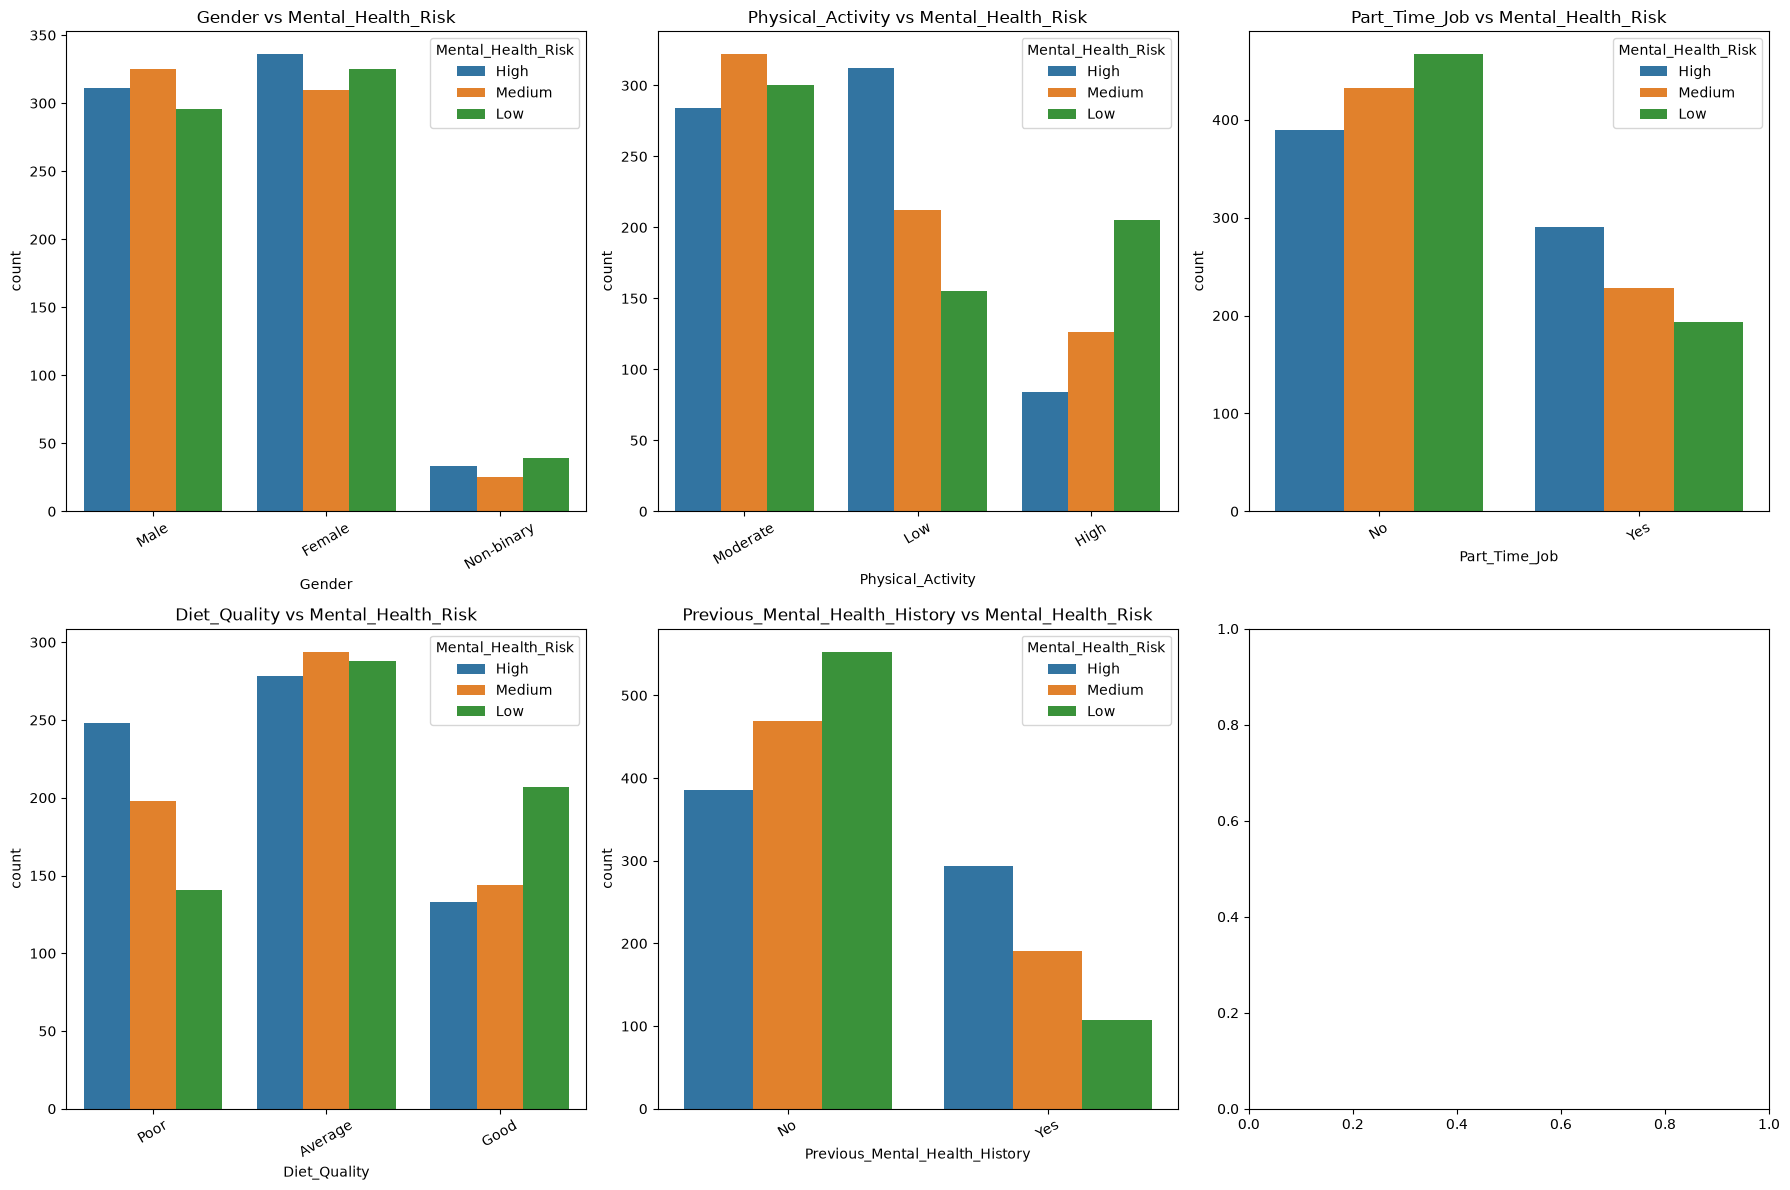

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(
        data=df,
        x=col,
        hue=target,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs {target}")
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 7.2 Relations entre les variables numériques et la cible

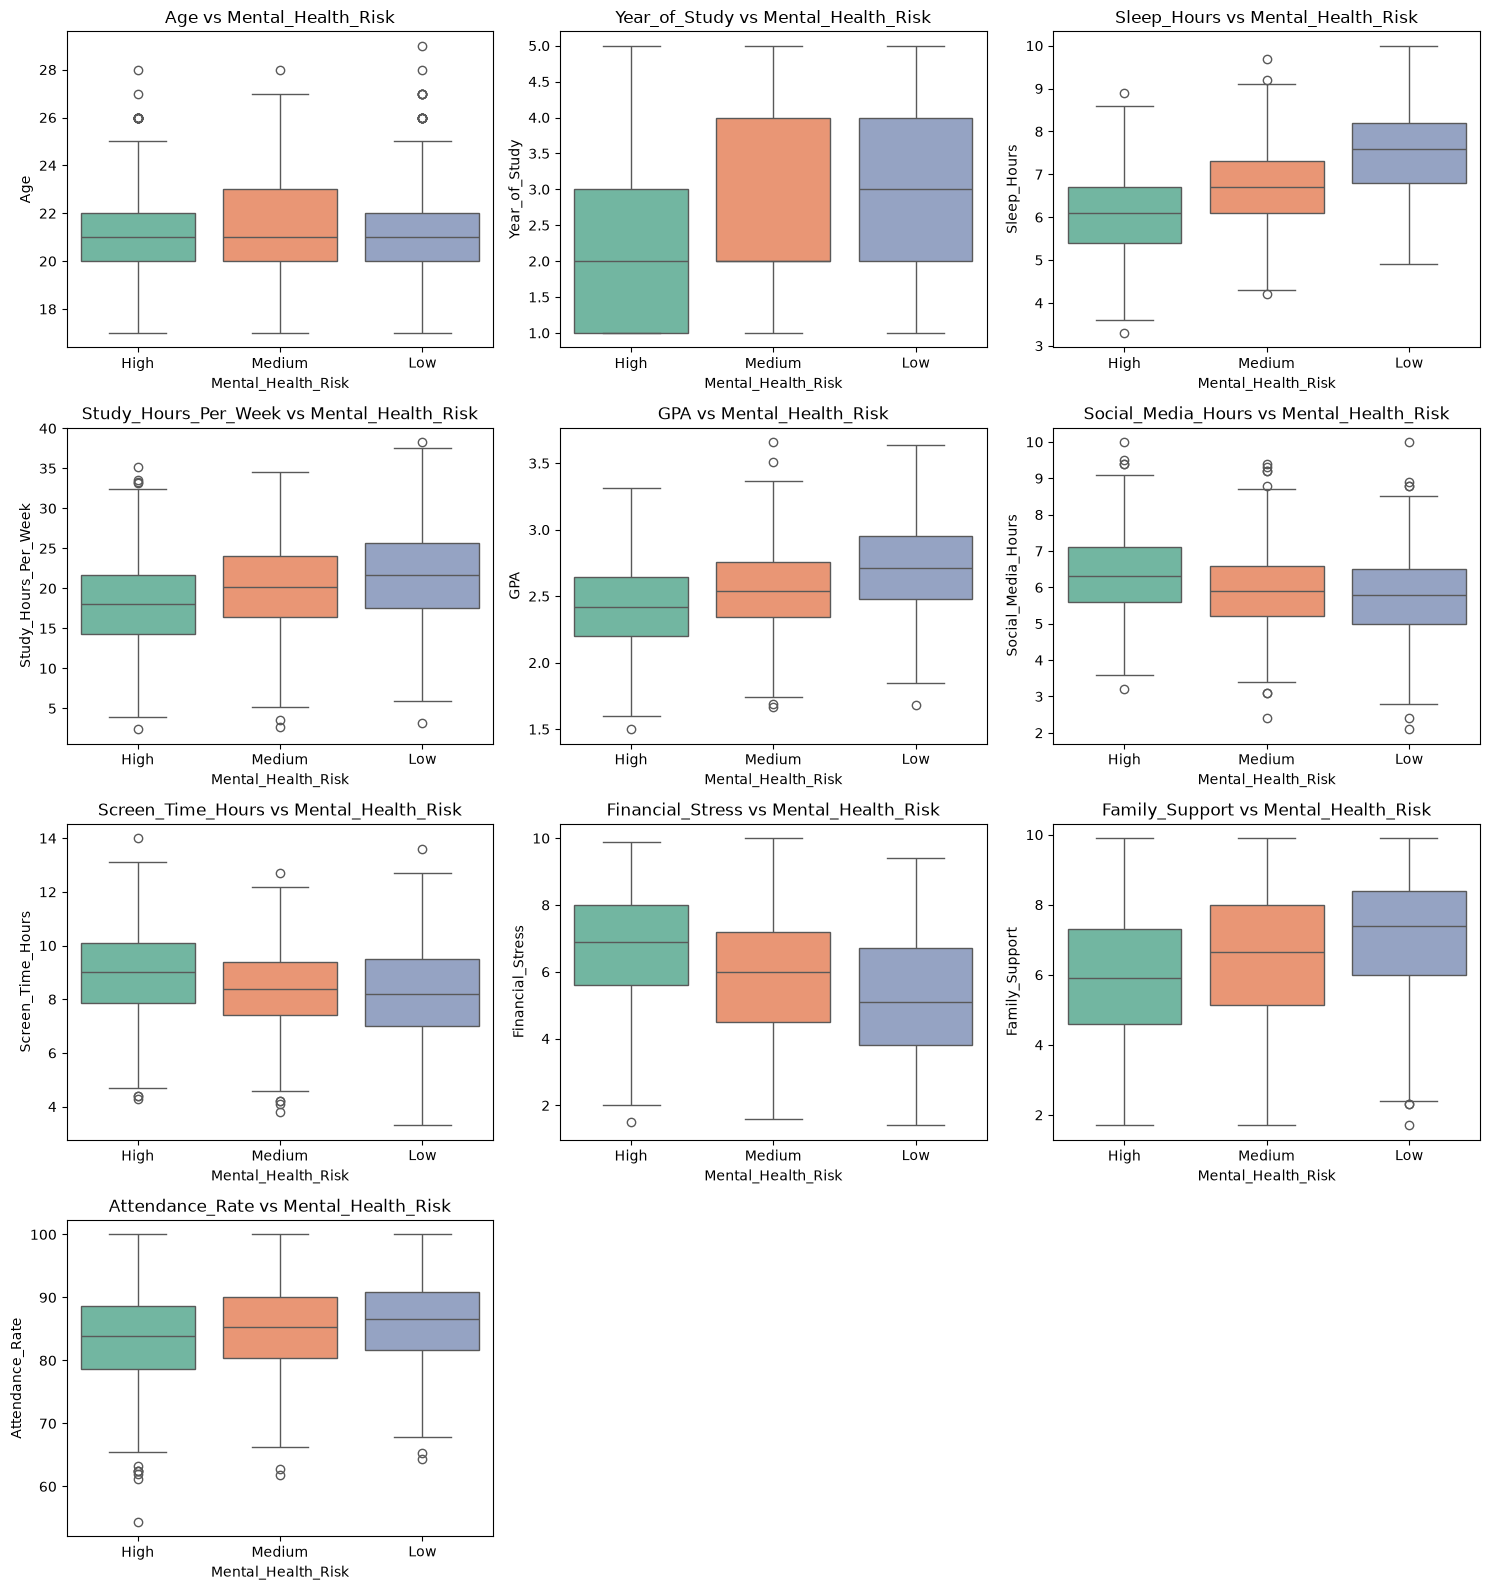

In [20]:
fig, axes = plt.subplots(4, 3, figsize=(15,16))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x=target,
        y=col,
        hue=target,
        ax=axes[i],
        palette="Set2",
        legend=False
    )

    axes[i].set_title(f"{col} vs {target}")

for i in range(10, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

## 8. Examiner les corrélations entre les variables

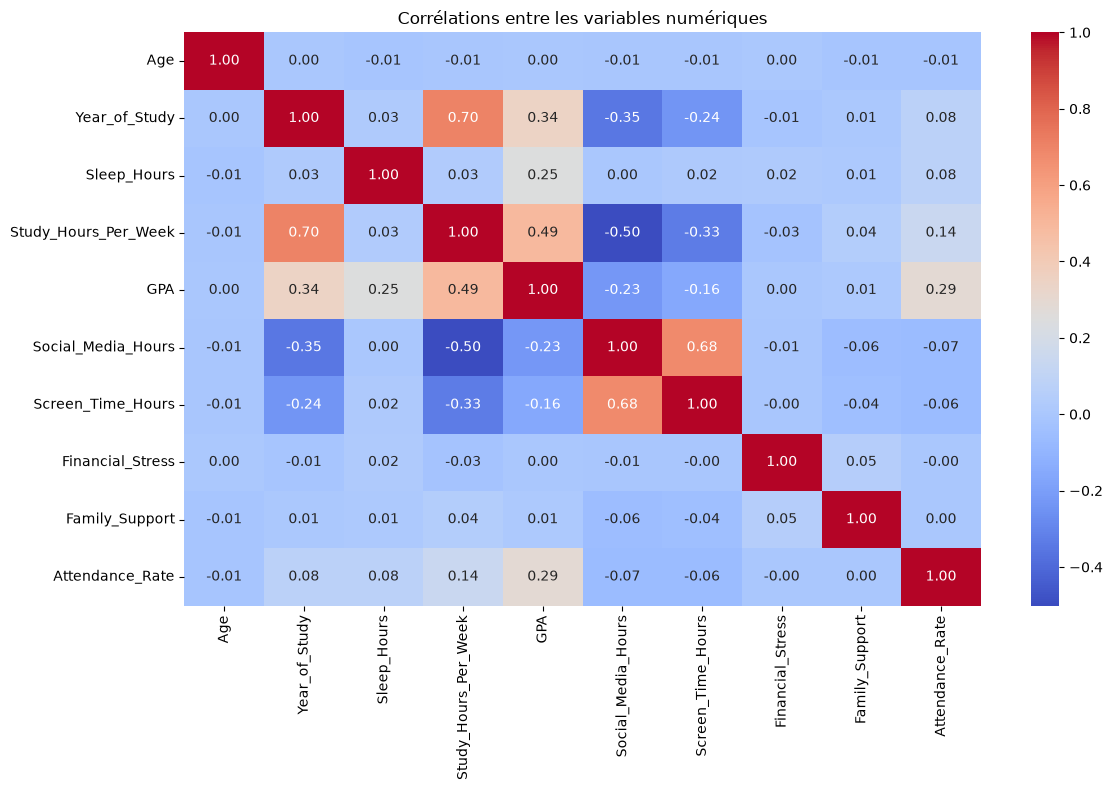

In [21]:
# Calculer les corrélations entre les variables numériques
correlation = df[numerical_features].corr()

# Afficher la matrice de corrélation
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Corrélations entre les variables numériques")
plt.tight_layout()
plt.show()

## 9. Identifier les variables les plus fortement liées au niveau de risque

À partir des graphiques des relations entre les variables explicatives et la cible, relever les variables qui montrent les différences les plus visibles entre les niveaux de risque.

Compléter cette partie avec les observations obtenues après l'exécution des cellules précédentes.

## Résumé de l'analyse

Présenter ici les principales observations issues de l'analyse :
- Structure générale du dataset.
- Valeurs manquantes, doublons et incohérences détectés.
- Valeurs aberrantes détectées.
- Statistiques descriptives.
- Distribution de la variable cible.
- Relations entre les variables explicatives et la cible.
- Corrélations entre les variables.
- Variables les plus fortement liées au niveau de risque.

### Transformation et préparation des données

Séparation des données

In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1600, 15)
X_test: (400, 15)


Traitement des valeurs manquantes

In [23]:
from sklearn.impute import SimpleImputer
# Variables numériques
num_imputer = SimpleImputer(strategy="median")
X_train[numerical_features] = num_imputer.fit_transform(X_train[numerical_features])
X_test[numerical_features] = num_imputer.transform(X_test[numerical_features])

# Variables catégorielles
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train[categorical_features] = cat_imputer.fit_transform(X_train[categorical_features])
X_test[categorical_features] = cat_imputer.transform(X_test[categorical_features])

Définition des variables

In [24]:
numerical_features = [
    'Age',
    'Year_of_Study',
    'Sleep_Hours',
    'Study_Hours_Per_Week',
    'GPA',
    'Social_Media_Hours',
    'Screen_Time_Hours',
    'Financial_Stress',
    'Family_Support',
    'Attendance_Rate'
]

categorical_features = [
    'Gender',
    'Part_Time_Job',
    'Previous_Mental_Health_History'
]

ordinal_features = [
    'Physical_Activity',
    'Diet_Quality'
]

Détection des Outliers

In [25]:
for col in numerical_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = X_train[
        (X_train[col] < Q1 - 1.5 * IQR) |
        (X_train[col] > Q3 + 1.5 * IQR)
    ]

    print(col, ":", len(outliers))

Age : 2
Year_of_Study : 0
Sleep_Hours : 9
Study_Hours_Per_Week : 7
GPA : 8
Social_Media_Hours : 16
Screen_Time_Hours : 7
Financial_Stress : 0
Family_Support : 0
Attendance_Rate : 10


Création des Pipelines

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

Pipeline catégorielle

In [27]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

Pipeline ordinale

In [28]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[
            ['Low', 'Moderate', 'High'],
            ['Poor', 'Average', 'Good']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

ColumnTransformer

In [29]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features),
    ('ord', ordinal_pipeline, ordinal_features)
])

Gestion du déséquilibre des classes

In [30]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Test:", X_test_processed.shape)

Train: (1600, 19)
Test: (400, 19)


### Justification des décisions

- **Median :** utilisée pour les variables numériques afin de limiter l'influence des valeurs aberrantes.
- **Most Frequent :** utilisée pour les variables catégorielles afin de remplacer les valeurs manquantes.
- **IQR :** utilisée pour détecter les valeurs aberrantes.
- **Outliers :** conservés car ils peuvent représenter des observations réelles.
- **OneHotEncoder :** utilisé pour encoder les variables nominales.
- **OrdinalEncoder :** utilisé pour encoder les variables ordinales tout en préservant leur ordre.
- **StandardScaler :** utilisé pour mettre les variables numériques à la même échelle.
- **SMOTE :** non nécessaire car les classes sont équilibrées.
- **Pipeline :** utilisé pour regrouper les transformations et éviter le Data Leakage.

## Entraînement et comparaison des modèles

Importation des modèles & Création des modèles

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True)
}

Entraînement des modèles

In [32]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully


c:\Users\Youcode\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully


Évaluation des modèles & Comparaison des modèles

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-score': f1_score(y_test, y_pred, average='weighted')
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7575,0.7576,0.7575,0.7575
1,Random Forest,0.6800,0.6772,0.6800,0.6785
2,SVM,0.7250,0.7238,0.7250,0.7243


Matrice de confusion

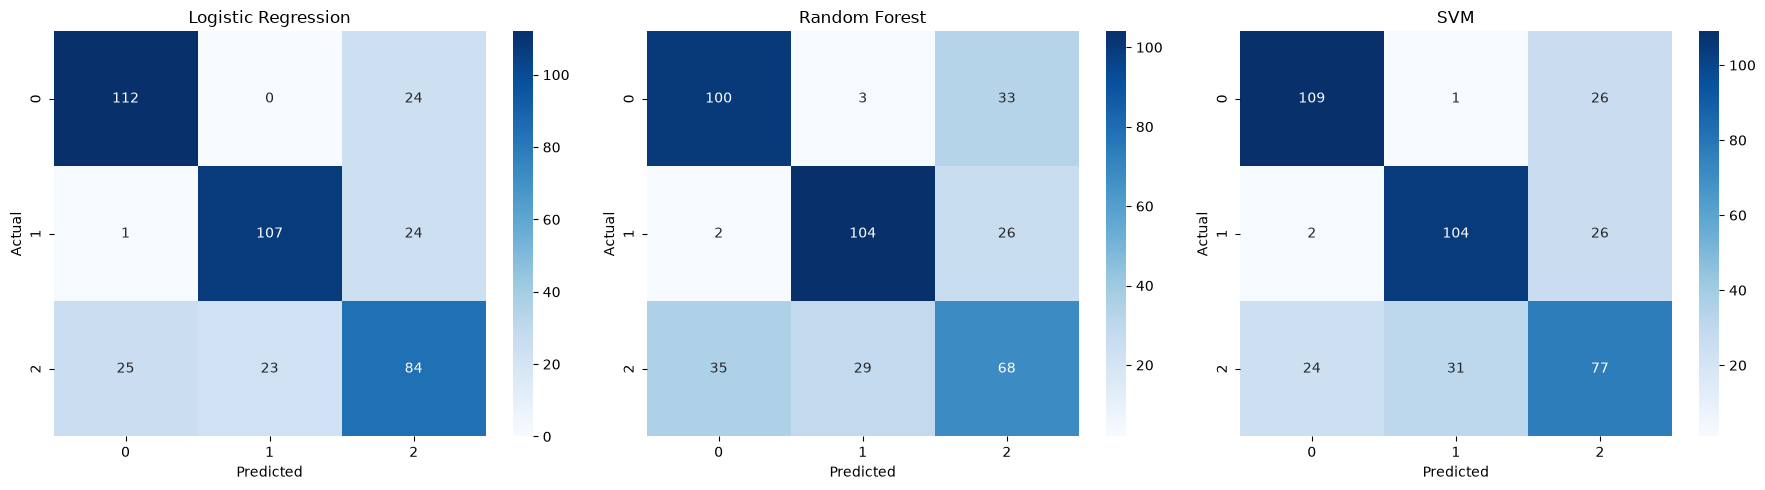

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Classification Report

In [35]:
from sklearn.metrics import classification_report

for name, model in trained_models.items():

    print("\n", name)
    print(classification_report(y_test, model.predict(X_test)))


 Logistic Regression
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.81      0.82       132
      Medium       0.64      0.64      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400


 Random Forest
              precision    recall  f1-score   support

        High       0.73      0.74      0.73       136
         Low       0.76      0.79      0.78       132
      Medium       0.54      0.52      0.53       132

    accuracy                           0.68       400
   macro avg       0.68      0.68      0.68       400
weighted avg       0.68      0.68      0.68       400


 SVM
              precision    recall  f1-score   support

        High       0.81      0.80      0.80       136
         Low       0.76      0.79      0.78       132
      Medium       0.60      0.

In [36]:
from sklearn.metrics import roc_auc_score

for name, model in trained_models.items():

    y_proba = model.predict_proba(X_test)

    auc = roc_auc_score(
        y_test,
        y_proba,
        multi_class='ovr',
        average='weighted',
        labels=model.classes_
    )

    print(name, "ROC-AUC:", round(auc, 4))

Logistic Regression ROC-AUC: 0.9144
Random Forest ROC-AUC: 0.8488
SVM ROC-AUC: 0.8906


## Optimisation avec GridSearchCV

In [37]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

Définition des modèles et hyperparamètres

In [38]:
models_params = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=2000),
        "params": {
            "model__C": [0.01, 0.1, 1, 10]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_split": [2, 5]
        }
    },

    "SVM": {
        "model": SVC(),
        "params": {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"],
            "model__gamma": ["scale", "auto"]
        }
    }
}

GridSearchCV

In [39]:
best_models = {}
best_results = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, config in models_params.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', config['model'])
    ])

    grid = GridSearchCV(
        pipeline,
        config['params'],
        cv=cv,
        scoring='f1_weighted',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    best_results.append({
        'Model': name,
        'Best Parameters': grid.best_params_,
        'Best F1-score': grid.best_score_
    })

    print(name, "Best Score:", grid.best_score_)

Logistic Regression Best Score: 0.7526375663606861
Random Forest Best Score: 0.6814801095250153
SVM Best Score: 0.7407490138524226


Comparaison des performances

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-score': f1_score(y_test, y_pred, average='weighted')
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7550,0.7555,0.7550,0.7552
1,Random Forest,0.7025,0.6999,0.7025,0.7010
2,SVM,0.7650,0.7646,0.7650,0.7648


##### Évaluation et matrice de confusion

In [41]:
best_model = best_models['SVM']

print("Best Model: SVM")
print("Accuracy:", accuracy_score(y_test, best_model.predict(X_test)))
print("Best Parameters:", best_results[2]['Best Parameters'])

Best Model: SVM
Accuracy: 0.765
Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


In [42]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = best_model.predict(X_test)
print("Accuracy :", accuracy_score(y_test, y_pred))

print("\nClassification Report :")
print(classification_report(y_test, y_pred))

Accuracy : 0.765

Classification Report :
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.83      0.83      0.83       132
      Medium       0.65      0.64      0.65       132

    accuracy                           0.77       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.77      0.76       400



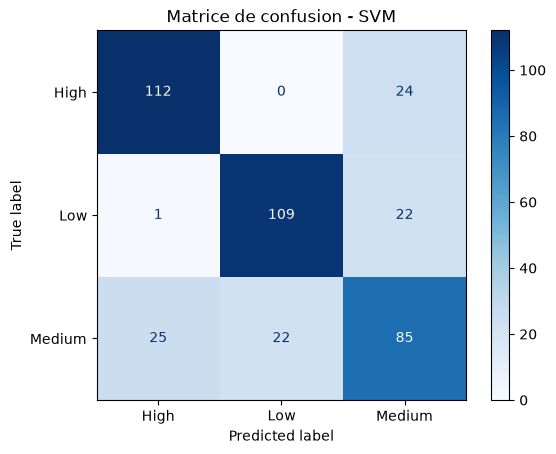

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot(cmap='Blues', values_format='d')

# Désactiver les lignes de la grille
disp.ax_.grid(False)

plt.title("Matrice de confusion - SVM")
plt.show()

Analyse des erreurs et des limites

In [44]:
errors = y_test != y_pred

print("Prédictions correctes :", errors.value_counts().get(False, 0))
print("Prédictions incorrectes :", errors.value_counts().get(True, 0))
print("Taux d'erreur :", round(errors.mean() * 100, 2), "%")

Prédictions correctes : 306
Prédictions incorrectes : 94
Taux d'erreur : 23.5 %


Exemples des prédictions incorrectes

In [45]:
errors_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

display(errors_df[errors_df['Actual'] != errors_df['Predicted']].head(10))

,Actual,Predicted
720,Low,Medium
1624,Medium,High
1854,High,Medium
1130,Medium,Low
1071,Medium,Low
1522,Medium,Low
911,Medium,Low
1887,Medium,High
1084,Medium,Low
1131,Medium,High


### Analyse des erreurs et des limites du modèle

L'analyse des prédictions montre que le modèle SVM présente de bonnes performances globales, avec une Accuracy de 76,5 %.

Cependant, certaines observations sont mal classées. Le modèle peut confondre certaines catégories, notamment lorsque les caractéristiques des étudiants sont similaires.

**Limites du modèle :**
- Le modèle ne prédit pas correctement toutes les observations.
- Certaines classes restent difficiles à distinguer.
- Les performances dépendent de la qualité et de la représentativité des données.
- Le modèle peut être amélioré en utilisant davantage de données et en testant d'autres techniques.

Enfin, ce modèle constitue un outil d'aide à la prédiction et ne doit pas être considéré comme un outil de diagnostic médical.

In [ ]:
import joblib

joblib.dump(best_model, '../models/mental_health_model.joblib')

print("./models/mental_health_model.joblib")

./models/mental_health_model.joblib
